In [9]:
%pip install liac-arff

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
import arff
import pandas as pd

with open("dataset.arff", "r", encoding="utf-8") as file:
    dataset = arff.load(file)

df = pd.DataFrame(
    dataset["data"],
    columns=[attr[0] for attr in dataset["attributes"]]
)

# Missing value
df = df.replace("?", pd.NA)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Rows and columns: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [11]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("All libraries imported successfully!")

All libraries imported successfully!


In [12]:
print("Dataset shape:", df.shape)
print("SalePrice column exists:", "SalePrice" in df.columns)
print("Target data type:", df["SalePrice"].dtype)

display(df[["SalePrice"]].head())

Dataset shape: (1460, 81)
SalePrice column exists: True
Target data type: int64


,SalePrice
0,208500
1,181500
2,223500
3,140000
4,250000


In [13]:
# Separate input features and target
X = df.drop(columns=["SalePrice", "Id"], errors="ignore")
y = df["SalePrice"]

# Split before preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1168, 79)
Testing features: (292, 79)
Training target: (1168,)
Testing target: (292,)


In [15]:
# Identify numerical columns
numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical columns
categorical_cols = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print("Number of numerical columns:", len(numerical_cols))
print("Number of categorical columns:", len(categorical_cols))

print("\nFirst 10 numerical columns:")
print(numerical_cols[:10])

print("\nFirst 10 categorical columns:")
print(categorical_cols[:10])

Number of numerical columns: 36
Number of categorical columns: 43

First 10 numerical columns:
['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2']

First 10 categorical columns:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1']


In [16]:
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical pipeline created!")

Numerical pipeline created!


In [17]:
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical pipeline created!")

Categorical pipeline created!


In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_cols),
        ("cat", categorical_pipeline, categorical_cols)
    ]
)

print("ColumnTransformer created!")

ColumnTransformer created!


In [19]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (1168, 286)
Testing data after preprocessing: (292, 286)


In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Combine preprocessing and model into one pipeline
model_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

# Train using training data only
model_pipeline.fit(X_train, y_train)

# Predict on unseen test data
y_pred = model_pipeline.predict(X_test)

print("Model training completed!")
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

Model training completed!
Mean Absolute Error: 17750.58373287671
R2 Score: 0.8876872398529598


In [21]:
import pandas as pd

# Get the trained Random Forest model
rf_model = model_pipeline.named_steps["model"]

# Get feature names after preprocessing
feature_names = (
    model_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Calculate feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

# Show top 15 features
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
3,num__OverallQual,0.555690
15,num__GrLivArea,0.120995
11,num__TotalBsmtSF,0.035323
13,num__2ndFlrSF,0.034529
8,num__BsmtFinSF1,0.028747
12,num__1stFlrSF,0.024946
2,num__LotArea,0.016523
26,num__GarageArea,0.016076
25,num__GarageCars,0.011760
5,num__YearBuilt,0.011005


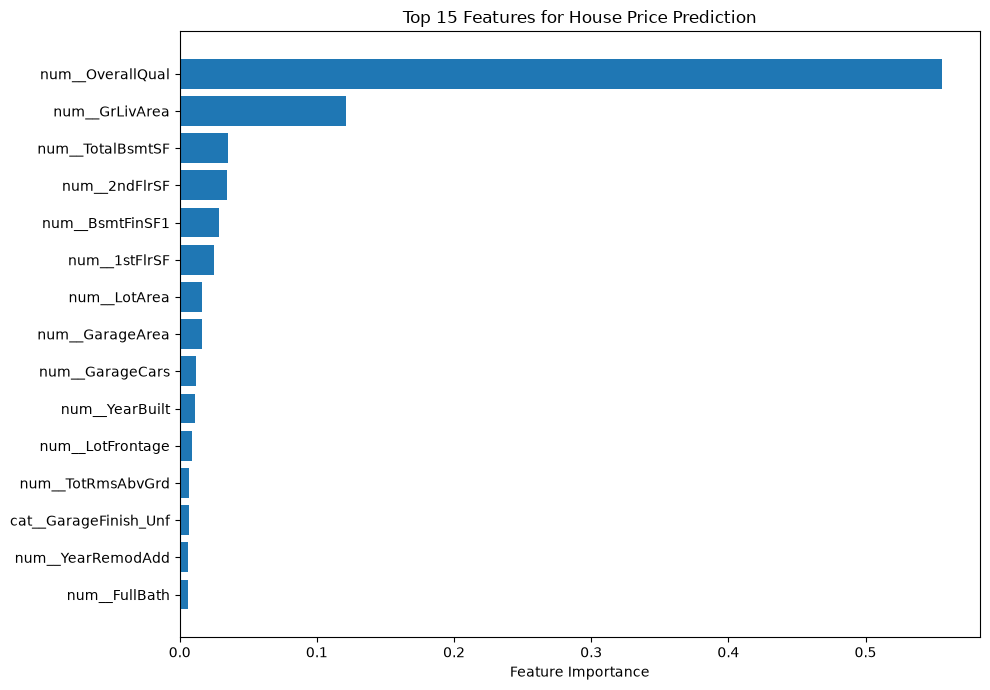

In [22]:
import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)
plt.xlabel("Feature Importance")
plt.title("Top 15 Features for House Price Prediction")
plt.tight_layout()
plt.show()